# 00. De dónde salen los datos

Teórica de series temporales, Analítica de Datos (UdeSA).

Los cuadernos 01 a 06 trabajan con los archivos de `datos_clase/`, que ya están limpios. Este cuaderno muestra de dónde salen y qué hubo que resolver para armarlos, con los archivos originales de los molinetes del subte.

Contenido:

1. Las fuentes y lo que hay en `datos_clase`.
2. Cómo vienen los archivos de molinetes: un formato distinto cada año.
3. Fechas en cuatro órdenes.
4. Un año completo, de punta a punta (opcional: descarga unos 90 MB).
5. Nombres de estación.

In [1]:
import sys

# Dirección de los datos cuando el notebook corre en Colab.
# Si los datos se suben a otro lado, hay que cambiar esta constante.
URL_DATOS_COLAB = "https://raw.githubusercontent.com/ferkrodriguez98/teorica-series-temporales/main/datos_clase/"

EN_COLAB = "google.colab" in sys.modules
BASE = URL_DATOS_COLAB if EN_COLAB else "../datos_clase/"
print("Datos:", BASE)

Datos: ../datos_clase/


In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter

# Colores: tinta para lo observado, rojo para pronósticos y resaltados
TINTA, GRIS, ROJO = "#1f2430", "#9aa0a6", "#c62828"
LINEAS = {"A": "#1a9fd0", "B": "#d7182a", "C": "#1d4f9c", "D": "#008a57", "E": "#6c2c87", "H": "#e0a800"}
ECOBICI = "#d4a017"

warnings.simplefilter("ignore", FutureWarning)   # avisos de cambios en versiones futuras de las librerías

plt.rcParams.update({
    "figure.figsize": (10, 3.6), "figure.dpi": 100, "savefig.bbox": "tight",
    "axes.grid": True, "grid.color": "#e6e6e6", "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#b0b0b0",
    "axes.titlesize": 11.5, "axes.titlelocation": "left", "axes.labelsize": 10,
    "axes.labelcolor": "#444444", "xtick.color": "#555555", "ytick.color": "#555555",
    "legend.frameon": False, "legend.fontsize": 9.5, "lines.linewidth": 1.1,
})

def num(x, dec=0):
    # Número con punto de miles y coma decimal
    return f"{x:,.{dec}f}".replace(",", "X").replace(".", ",").replace("X", ".")

def pct(x, dec=0):
    return num(100 * x, dec) + " %"

en_millones = FuncFormatter(lambda v, _: num(v / 1e6, 1))
en_miles = FuncFormatter(lambda v, _: num(v / 1e3))

import io
import re
import urllib.request
import zipfile

## 1. Las fuentes

| Datos | Fuente |
|---|---|
| Molinetes del subte: pasajeros cada 15 minutos por molinete, 2013 a 2026 | SBASE, [BA Data: subte, viajes por molinetes](https://data.buenosaires.gob.ar/dataset/subte-viajes-molinetes) |
| Ecobici: un registro por viaje, 2014 a 2026 | [BA Data: bicicletas públicas](https://data.buenosaires.gob.ar/dataset/bicicletas-publicas) |
| Lluvia y temperatura diarias en la Ciudad | [Open-Meteo, Historical Weather API](https://open-meteo.com/en/docs/historical-weather-api) (reanálisis) |
| Feriados y días no laborables | decretos y leyes de cada año, contrastados con el calendario oficial de [argentina.gob.ar](https://www.argentina.gob.ar/feriados) |
| Índice de precios al consumidor | IPC de la Ciudad (DGEyC) hasta noviembre de 2016; IPC nacional (INDEC) desde diciembre de 2016 |
| Tarifa del subte | resoluciones del Directorio de SBASE en el Boletín Oficial de la Ciudad |
| Dólar blue | [Bluelytics](https://bluelytics.com.ar) |
| Días atípicos y qué pasó en cada uno | notas de prensa y normas, citadas en cada fila de `eventos_verificados.csv` |

Los archivos de molinetes y de Ecobici pesan varios gigabytes. `datos_clase` tiene resúmenes: por día, por día y estación, cada 15 minutos por línea, y por hora en Ecobici.

In [3]:
archivos = {
    "subte_diario_total.csv": "fecha", "subte_diario_linea.csv": "fecha", "subte_diario_estacion.csv.gz": "fecha",
    "subte_15min_linea.csv.gz": "fecha", "ecobici_diario.csv": "fecha", "ecobici_hora.csv": "fecha",
    "clima_diario.csv": "fecha", "feriados.csv": "fecha", "ipc_mensual.csv": "mes",
    "precio_boleto_mensual.csv": "mes", "dolar_blue.csv": "fecha", "eventos_verificados.csv": "fecha",
}
resumen = {}
for nombre, col in archivos.items():
    df = pd.read_csv(BASE + nombre)
    resumen[nombre] = {"filas": len(df), "columnas": ", ".join(df.columns), "desde": df[col].min(), "hasta": df[col].max()}
pd.DataFrame(resumen).T

,filas,columnas,desde,hasta
subte_diario_total.csv,4840,"fecha, pax",2013-06-01,2026-08-31
subte_diario_linea.csv,29193,"fecha, linea, pax",2013-06-01,2026-08-31
subte_diario_estacion.csv.gz,402988,"fecha, linea, estacion, pax",2013-06-01,2026-08-31
subte_15min_linea.csv.gz,2061519,"fecha, desde, linea, pax",2013-06-01,2026-08-31
ecobici_diario.csv,4255,"fecha, viajes, duracion_mediana_min",2014-01-02,2026-09-30
ecobici_hora.csv,102120,"fecha, hora, viajes",2014-01-02,2026-09-30
clima_diario.csv,4917,"fecha, precipitacion_mm, temp_max, temp_min, t...",2013-06-01,2026-11-16
feriados.csv,274,"fecha, nombre, tipo, caracter_legal, ambito, f...",2013-01-01,2026-12-25
ipc_mensual.csv,167,"mes, indice, fuente",2013-01,2026-11
precio_boleto_mensual.csv,162,"mes, precio_dia_15, precio_promedio_ponderado_...",2013-06,2026-11


## 2. Cómo vienen los archivos de molinetes

BA Data publica un zip por año en `https://cdn.buenosaires.gob.ar/datosabiertos/datasets/sbase/subte-viajes-molinetes/molinetes-AAAA.zip` (2014 a 2026). Cada uno pesa entre 37 y 126 MB.

Para ver cómo empieza cada archivo no hace falta bajarlo entero. Un zip guarda al final un índice con la posición de cada archivo comprimido, y el servidor acepta pedidos de rango (*HTTP Range*): se puede leer el índice y los primeros kilobytes de cada CSV. La clase `ArchivoRemoto` hace eso; `zipfile` la usa como si fuera un archivo local.

In [4]:
URL_MOLINETES = "https://cdn.buenosaires.gob.ar/datosabiertos/datasets/sbase/subte-viajes-molinetes/molinetes-{}.zip"

class ArchivoRemoto(io.RawIOBase):
    # Archivo de solo lectura sobre HTTP: cada lectura pide al servidor solo los bytes necesarios.
    def __init__(self, url):
        self.url, self.pos, self.bajados = url, 0, 0
        with urllib.request.urlopen(urllib.request.Request(url, method="HEAD")) as r:
            self.tam = int(r.headers["Content-Length"])
    def readable(self): return True
    def seekable(self): return True
    def tell(self): return self.pos
    def seek(self, desplazamiento, desde=0):
        self.pos = {0: desplazamiento, 1: self.pos + desplazamiento, 2: self.tam + desplazamiento}[desde]
        return self.pos
    def readinto(self, buffer):
        n = min(len(buffer), self.tam - self.pos)
        if n <= 0:
            return 0
        pedido = urllib.request.Request(self.url, headers={"Range": f"bytes={self.pos}-{self.pos + n - 1}"})
        with urllib.request.urlopen(pedido) as r:
            datos = r.read()
        buffer[:len(datos)] = datos
        self.pos += len(datos)
        self.bajados += len(datos)
        return len(datos)

def primeras_lineas(anio, n=2):
    remoto = ArchivoRemoto(URL_MOLINETES.format(anio))
    z = zipfile.ZipFile(io.BufferedReader(remoto, buffer_size=1 << 16))
    csvs = [i for i in z.infolist() if i.filename.lower().endswith(".csv")]
    with z.open(csvs[0]) as f:
        crudo = f.read(2000)
    texto = crudo.decode("utf-8-sig", errors="replace")
    lineas = texto.splitlines()[:n]
    return {"archivos CSV": len(csvs), "primer archivo": csvs[0].filename.split("/")[-1],
            "MB del zip": round(remoto.tam / 1e6), "KB leídos": round(remoto.bajados / 1e3),
            "encabezado": lineas[0], "primera fila": lineas[1]}

In [5]:
pd.set_option("display.max_colwidth", 200)
try:
    formatos = pd.DataFrame({anio: primeras_lineas(anio) for anio in range(2014, 2027)}).T
except Exception as error:
    formatos = None
    print("No se pudo leer desde BA Data (¿sin conexión?):", error)
formatos

,archivos CSV,primer archivo,MB del zip,KB leídos,encabezado,primera fila
2014,1,molinetes_2014.csv,78,66,"""FECHA"",""DESDE"",""HASTA"",""LINEA"",""MOLINETE"",""ID_ESTACION"",""ESTACION"",""PAX_PAGO"",""PAX_PASES_PAGOS"",""PAX_FRANQ"",""PAX_TOTAL""","2014-04-09,09:15:00,09:29:00,""B"",""LINEA_B_FLORIDA_E_TURN02"",20,""FLORIDA"",7,NA,NA,7"
2015,1,molinetes-2015.csv,109,66,"periodo,fecha,desde,hasta,linea,molinete,estacion,pax_pagos,pax_pases_pagos,pax_franq,total","201501,2015-01-01,05:00:00,05:15:00,LINEA_H,LINEA_H_CASEROS_NORTE_TURN01,CASEROS,0.0,0.0,0.0,0.0"
2016,1,molinetes_2016.csv,81,66,"""FECHA"",""DESDE"",""HASTA"",""LINEA"",""MOLINETE"",""ID_ESTACION"",""ESTACION"",""PAX_PAGOS"",""PAX_PASES_PAGOS"",""PAX_FREQ"",""TOTAL""","""02/01/2016"",""05:00:00"",""05:15:00"",""D"",""LINEA_D_9JULIO_S_TURN02"",6,""9 DE JULIO"",1,0,0,1"
2017,1,molinetes_2017.csv,122,66,"""V1"",""FECHA"",""DESDE"",""HASTA"",""LINEA"",""MOLINETE"",""ID_ESTACION"",""ESTACION"",""PAX_PAGOS"",""PAX_PASES_PAGOS"",""PAX_FREQ"",""TOTAL""","1,""01/01/2017"",""08:00:00"",""08:15:00"",""D"",""LINEA_D_9JULIO_S_TURN02"",6,""9 DE JULIO"",1,0,0,1"
2018,1,molinetes-subte-18.csv,122,66,"fecha,desde,hasta,linea,molinete,estacion,pax_pagos,pax_pases_pagos,pax_franq,total,periodo","2018-01-01,08:00:00,08:15:00,LineaA,LineaA_CBarros_S_Turn01,Castro Barros,1.0,0.0,0.0,1.0,201801"
2019,1,datahistorica122019.csv,126,66,"periodo,fecha,desde,hasta,linea,molinete,estacion,pax_pagos,pax_pases_pagos,pax_franq,total","201901,2019-01-01,08:00:00,08:15:00,LineaA,LineaA_Lima_N_Turn02,Lima,1.0,0.0,0.0,1.0"
2020,1,historico2.csv,37,66,"FECHA,DESDE,HASTA,LINEA,MOLINETE,ESTACION,pax_pagos,pax_pases_pagos,pax_franq,pax_TOTAL","01/01/2020,08:00:00,08:15:00,LineaA,LineaA_Acoyte_N_Turn01,Acoyte,1,0,0,1"
2021,1,historico_2021.csv,52,66,periodo;FECHA;DESDE;HASTA;LINEA;MOLINETE;ESTACION;pax_pagos;pax_pases_pagos;pax_franq;pax_TOTAL,2021;1/1/2021;08:00:00;08:15:00;LineaA;LineaA_Flores_Este_Turn02;Flores;1;0;0;1
2022,24,202201_PAX15min-ABC.csv,83,68,"""FECHA;DESDE;HASTA;LINEA;MOLINETE;ESTACION;pax_pagos;pax_pases_pagos;pax_franq;pax_TOTAL""","""1/1/2022;07:45:00;08:00:00;LineaA;LineaA_Carabobo_E_Turn02;Carabobo;1;0;0;1"""
2023,24,202301_PAX15min-ABC.csv,83,68,"""FECHA;DESDE;HASTA;LINEA;MOLINETE;ESTACION;pax_pagos;pax_pases_pagos;pax_franq;pax_TOTAL""","""1/1/2023;07:45:00;08:00:00;LineaB;LineaB_Alem_S_Turn04;Leandro N. Alem;0;0;2;2"""


In [6]:
if formatos is not None:
    def separador(linea):
        return ";" if linea.count(";") > linea.count(",") else ","
    def comillas(linea):
        linea = linea.strip()
        if linea.startswith('"') and linea.rstrip(";").endswith('"') and linea.count('"') == 2:
            return "toda la línea"
        return "en los textos" if '"' in linea else "sin comillas"
    def campo_fecha(f):
        sep = separador(f["encabezado"])
        cabecera = [c.strip('"').lower() for c in f["encabezado"].strip().strip('"').split(sep)]
        valores = f["primera fila"].strip().rstrip(";").strip('"').split(sep)
        return valores[cabecera.index("fecha")].strip('"')
    pd.DataFrame({
        "separador": formatos["primera fila"].map(separador),
        "comillas": formatos["primera fila"].map(comillas),
        "fecha de la primera fila": formatos.apply(campo_fecha, axis=1),
        "archivos CSV": formatos["archivos CSV"],
    })

Lo que hay que resolver, mirando solo las primeras líneas:

- **Separador**: coma hasta 2020, punto y coma desde 2021.
- **Comillas**: algunos años encierran los textos entre comillas; desde 2022 cada línea entera viene entre comillas, con los separadores adentro, así que un lector de CSV común ve una sola columna.
- **Columnas**: cambian de nombre y de orden (`PAX_TOTAL`, `total`, `pax_TOTAL`), algunos años agregan una columna `periodo` o un contador de filas (`V1`), y en agosto de 2026 aparece una columna `origen`.
- **Línea**: `"B"`, `LINEA_H`, `LineaA` o `LineaPM`, según el año.
- **Archivos**: uno por año hasta 2021; desde 2022, dos o tres por mes (líneas A, B y C; D, E y H; Premetro).
- **Fechas**: año-mes-día en unos años, día/mes/año en otros, con o sin ceros a la izquierda.

## 3. Fechas en cuatro órdenes

Una fecha como `02/01/2016` puede ser el 2 de enero o el 1 de febrero. Cuando los dos números son 12 o menos, el texto solo no alcanza para decidir. En los archivos de molinetes aparecen cuatro órdenes:

| Orden | Ejemplo | Dónde aparece |
|---|---|---|
| día/mes | `31/01/2020`, `13/1/2021` | enero y febrero de 2020; la mayor parte de 2021 |
| mes/día | `3/13/2020`, `8/13/2025` | de marzo a diciembre de 2020; parte del archivo de agosto de 2025 |
| año-mes-día | `2021-02-13` | del 13 al 28 de febrero y del 13 al 31 de marzo de 2021 |
| año-día-mes | `2021-01-02` (el 1 de febrero) | del 1 al 12 de febrero y de marzo de 2021 |

Lo que hace pandas con algunos de esos textos:

In [7]:
ejemplos = pd.Series(["02/01/2016", "3/13/2020", "3/1/2020", "2021-02-13", "2021-01-02"])
pd.DataFrame({
    "texto": ejemplos,
    "pd.to_datetime (por defecto)": pd.to_datetime(ejemplos, format="mixed").dt.strftime("%d/%m/%Y"),
    "con dayfirst=True": pd.to_datetime(ejemplos, format="mixed", dayfirst=True).dt.strftime("%d/%m/%Y"),
})

,texto,pd.to_datetime (por defecto),con dayfirst=True
0,02/01/2016,01/02/2016,02/01/2016
1,3/13/2020,13/03/2020,13/03/2020
2,3/1/2020,01/03/2020,03/01/2020
3,2021-02-13,13/02/2021,13/02/2021
4,2021-01-02,02/01/2021,01/02/2021


Por defecto, pandas lee primero el mes: `02/01/2016` queda como 1 de febrero. Con `dayfirst=True` lee primero el día, y entonces `3/1/2020` queda como 3 de enero aunque en ese archivo signifique 1 de marzo. Ninguna opción única sirve para todos los archivos.

La salida está en el orden de las filas. Dentro de cada archivo, las filas de un mismo día vienen juntas y los días van en orden. Entonces se puede trabajar por **tramos** (filas seguidas con el mismo texto de fecha): un tramo ambiguo toma el mes del siguiente tramo que no es ambiguo. Los días 1 a 12 de cada mes vienen antes que el 13, que ya no es ambiguo. Así se resuelven los archivos anuales de 2020 y 2021.

En los archivos mensuales (desde 2022) eso no alcanza: en el de agosto de 2025, por ejemplo, una parte de los bloques viene ordenada como texto (`1/8/2025`, `10/8/2025`, `11/8/2025`...) y otra parte en mes/día (`8/1/2025`, `8/10/2025`...). Ahí el mes sale del nombre del archivo (`202508_...`): de las dos lecturas de `8/6/2025`, la que cae en agosto es el 6 de agosto.

In [8]:
def lecturas(cruda):
    # Fechas posibles para un texto de fecha: lista de (orden, fecha), sin repetir fechas
    partes = re.split(r"[/-]", cruda.strip())
    a, b, c = (int(x) for x in partes)
    if len(partes[0]) == 4:
        candidatas = [("año-mes-día", a, b, c), ("año-día-mes", a, c, b)]
    else:
        candidatas = [("día/mes", c, b, a), ("mes/día", c, a, b)]
    salida = {}
    for orden, anio, mes, dia in candidatas:
        try:
            fecha = pd.Timestamp(anio, mes, dia)
        except ValueError:
            continue
        if fecha in salida:
            salida[fecha] = "da lo mismo"
        else:
            salida[fecha] = orden
    return [(orden, fecha) for fecha, orden in salida.items()]

def resolver(crudas):
    # Elige una lectura para cada tramo usando el mes del tramo no ambiguo más cercano (primero el siguiente)
    opciones = [lecturas(c) for c in crudas]
    n = len(opciones)
    mes_siguiente, mes_anterior = [None] * n, [None] * n
    m = None
    for i in range(n - 1, -1, -1):
        mes_siguiente[i] = m
        if len(opciones[i]) == 1:
            m = opciones[i][0][1].month
    m = None
    for i in range(n):
        mes_anterior[i] = m
        if len(opciones[i]) == 1:
            m = opciones[i][0][1].month
    elegidas = []
    for i, ops in enumerate(opciones):
        if len(ops) == 1:
            elegidas.append(ops[0])
        else:
            elegida = next((o for o in ops if o[1].month == mes_siguiente[i]), None) \
                or next((o for o in ops if o[1].month == mes_anterior[i]), None) or ops[0]
            elegidas.append(elegida)
    return elegidas

prueba = ["30/1/2021", "31/1/2021", "2021-01-02", "2021-02-02", "2021-12-02", "2021-02-13", "2021-02-14"]
pd.DataFrame([{"texto": c, "lecturas posibles": " o ".join(f.strftime("%d/%m") for _, f in lecturas(c)),
               "elegida": f.strftime("%d/%m/%Y"), "orden": o} for c, (o, f) in zip(prueba, resolver(prueba))])

,texto,lecturas posibles,elegida,orden
0,30/1/2021,30/01,30/01/2021,día/mes
1,31/1/2021,31/01,31/01/2021,día/mes
2,2021-01-02,02/01 o 01/02,01/02/2021,año-día-mes
3,2021-02-02,02/02,02/02/2021,da lo mismo
4,2021-12-02,02/12 o 12/02,12/02/2021,año-día-mes
5,2021-02-13,13/02,13/02/2021,año-mes-día
6,2021-02-14,14/02,14/02/2021,año-mes-día


## 4. Un año completo (opcional)

Esta sección baja los archivos de 2020 (37 MB) y 2021 (52 MB), los lee en memoria (no se guardan en disco) y arma el total diario de cada año con tres criterios para las fechas: el de pandas por defecto, `dayfirst=True` y la resolución por tramos. Tarda alrededor de un minuto. Para saltearla, poner `DESCARGAR = False`.

In [9]:
DESCARGAR = True
ANIOS = [2020, 2021]

def tramos_de_un_anio(anio):
    with urllib.request.urlopen(URL_MOLINETES.format(anio)) as r:
        contenido = r.read()
    z = zipfile.ZipFile(io.BytesIO(contenido))
    nombre = [n for n in z.namelist() if n.lower().endswith(".csv")][0]
    encabezado = z.open(nombre).readline().decode("utf-8-sig").strip()
    sep = ";" if encabezado.count(";") > encabezado.count(",") else ","
    columnas = [c.strip('"') for c in encabezado.split(sep)]
    col_fecha = next(c for c in columnas if c.lower() == "fecha")
    col_pax = next(c for c in columnas if c.lower() in ("pax_total", "total"))
    df = pd.read_csv(z.open(nombre), sep=sep, usecols=[col_fecha, col_pax], dtype={col_fecha: "category"})
    sin_fecha = int(df[col_fecha].isna().sum())
    df = df.dropna(subset=[col_fecha])
    print(f"{anio}: {nombre}, {num(len(df))} filas, separador {sep!r} ({sin_fecha} filas sin fecha descartadas)")
    codigos = df[col_fecha].cat.codes.to_numpy()
    nuevo = np.r_[True, codigos[1:] != codigos[:-1]]          # empieza un tramo cuando cambia el texto de la fecha
    tramo = np.cumsum(nuevo) - 1
    return pd.DataFrame({
        "cruda": df[col_fecha].astype(str).to_numpy()[nuevo],
        "pax": np.bincount(tramo, weights=df[col_pax].fillna(0).to_numpy()),
    })

tramos = {}
if DESCARGAR:
    try:
        for anio in ANIOS:
            tramos[anio] = tramos_de_un_anio(anio)
    except Exception as error:
        print("No se pudo descargar:", error)
for anio, t in tramos.items():
    print(anio, ":", len(t), "tramos,", t["cruda"].nunique(), "textos de fecha distintos")

2020: historico2.csv, 5.779.170 filas, separador ',' (1836 filas sin fecha descartadas)


2021: historico_2021.csv, 8.071.680 filas, separador ';' (0 filas sin fecha descartadas)


2020 : 487 tramos, 350 textos de fecha distintos
2021 : 514 tramos, 364 textos de fecha distintos


In [10]:
for anio, t in tramos.items():
    elegidas = resolver(list(t["cruda"]))
    t["orden"] = [o for o, _ in elegidas]
    t["fecha"] = [f for _, f in elegidas]
    t["por defecto"] = pd.to_datetime(t["cruda"], format="mixed")
    t["dayfirst"] = pd.to_datetime(t["cruda"], format="mixed", dayfirst=True)

if tramos:
    display(pd.DataFrame({anio: t["orden"].value_counts() for anio, t in tramos.items()}).fillna(0).astype(int).rename_axis("orden del tramo"))
    display(tramos[ANIOS[-1]].iloc[28:48][["cruda", "orden", "fecha", "por defecto", "dayfirst"]])

,2020,2021
orden del tramo,,
año-día-mes,0,33
año-mes-día,0,51
da lo mismo,16,17
día/mes,234,413
mes/día,237,0


,cruda,orden,fecha,por defecto,dayfirst
28,29/1/2021,día/mes,2021-01-29,2021-01-29,2021-01-29
29,30/1/2021,día/mes,2021-01-30,2021-01-30,2021-01-30
30,31/1/2021,día/mes,2021-01-31,2021-01-31,2021-01-31
31,2021-01-02,año-día-mes,2021-02-01,2021-01-02,2021-02-01
32,2021-02-02,da lo mismo,2021-02-02,2021-02-02,2021-02-02
33,2021-03-02,año-día-mes,2021-02-03,2021-03-02,2021-02-03
34,2021-04-02,año-día-mes,2021-02-04,2021-04-02,2021-02-04
35,2021-05-02,año-día-mes,2021-02-05,2021-05-02,2021-02-05
36,2021-06-02,año-día-mes,2021-02-06,2021-06-02,2021-02-06
37,2021-07-02,año-día-mes,2021-02-07,2021-07-02,2021-02-07


"da lo mismo" son textos como `5/5/2020`, que dan la misma fecha en los dos órdenes. La tabla de abajo muestra el paso de enero a febrero de 2021: después del 31/1 vienen `2021-01-02`, `2021-02-02`... que son el 1, el 2... de febrero escritos como año-día-mes.

Con cada criterio se arma el total por día y se compara con `subte_diario_total.csv`:

In [11]:
total = pd.read_csv(BASE + "subte_diario_total.csv", parse_dates=["fecha"], index_col="fecha")["pax"]

diarios, filas = {}, []
for anio, t in tramos.items():
    calendario = pd.date_range(f"{anio}-01-01", f"{anio}-12-31")
    oficial = total.reindex(calendario)
    for criterio in ("por defecto", "dayfirst", "fecha"):
        d = t.groupby(criterio)["pax"].sum().reindex(calendario)
        diarios[(anio, criterio)] = d
        distinto = ~np.isclose(d.fillna(-1), oficial.fillna(-1), rtol=0.005)
        filas.append({"año": anio, "criterio": "por tramos" if criterio == "fecha" else criterio,
                      "días sin datos": int(d.isna().sum()),
                      "días distintos de datos_clase (más de 0,5 %)": int(distinto.sum())})
pd.DataFrame(filas) if filas else None

,año,criterio,días sin datos,"días distintos de datos_clase (más de 0,5 %)"
0,2020,por defecto,32,76
1,2020,dayfirst,32,120
2,2020,por tramos,0,0
3,2021,por defecto,1,132
4,2021,dayfirst,1,0
5,2021,por tramos,1,0


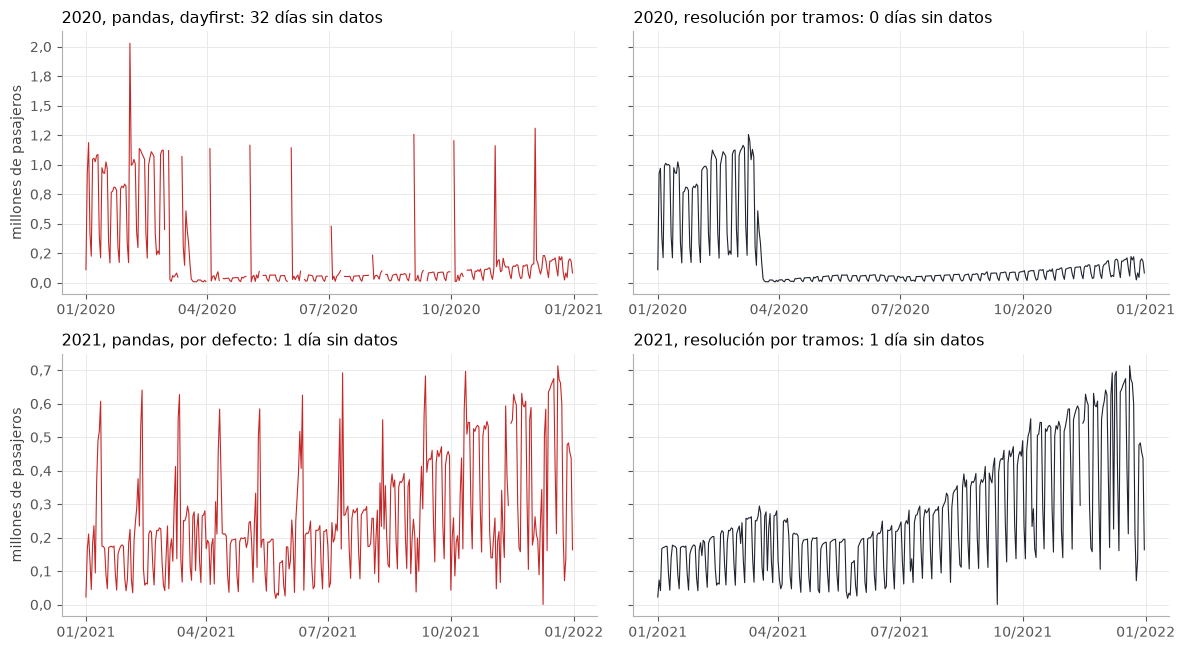

In [12]:
if diarios:
    fig, axes = plt.subplots(len(ANIOS), 2, figsize=(12, 3.3 * len(ANIOS)), sharey="row", squeeze=False)
    for fila, (anio, ingenuo) in enumerate(zip(ANIOS, ("dayfirst", "por defecto"))):
        for col, criterio in enumerate((ingenuo, "fecha")):
            d = diarios[(anio, criterio)]
            ax = axes[fila, col]
            ax.plot(d.index, d.values, color=ROJO if col == 0 else TINTA, lw=0.8)
            nombre = "resolución por tramos" if criterio == "fecha" else f"pandas, {criterio}"
            faltan = int(d.isna().sum())
            ax.set_title(f"{anio}, {nombre}: {faltan} {'día' if faltan == 1 else 'días'} sin datos")
            ax.yaxis.set_major_formatter(en_millones)
            ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
            ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%Y"))
        axes[fila, 0].set_ylabel("millones de pasajeros")
    fig.tight_layout()

Con `dayfirst=True`, en 2020 los días 1 a 12 de cada mes desde marzo quedan cambiados de lugar: los pasajeros del 1 de abril (`4/1/2020`) aparecen el 4 de enero, por ejemplo, y hay días con el doble de lo normal y días vacíos. En 2021, en cambio, `dayfirst=True` da el resultado correcto, pero por casualidad: lee `2021-01-02` como año-día-mes, que es justo como vienen esos días. Con la lectura por defecto, en 2021 los días 1 a 12 escritos como día/mes se leen como mes/día y el año queda desordenado. En ningún caso hay un error ni un aviso: el resultado es una serie con números razonables a primera vista.

Este problema llegó a los datos de la clase. En una primera versión, los 20 días del 1 al 12 de febrero y de marzo de 2021 aparecían vacíos, y sus pasajeros sumados a los días 2 y 3 de otros meses: el 2/1/2021 tenía los del 1 de febrero, el 2/4 los del 4 de febrero, y así. El exceso de esos días receptores coincidía, con una diferencia de 0,5 %, con lo que se esperaba para los 20 días vacíos. La columna "días distintos de datos_clase" de la tabla de arriba muestra si los archivos actuales coinciden con la resolución por tramos.

## 5. Nombres de estación

Los nombres de estación también cambian de un año a otro: mayúsculas o no, con o sin tildes, abreviados (`PZA. DE LOS VIRREYES`), y con caracteres mal codificados en algunos archivos. Ejemplos en `subte_diario_estacion.csv.gz`, donde los nombres ya están en mayúsculas y sin tildes:

In [13]:
est = pd.read_csv(BASE + "subte_diario_estacion.csv.gz", parse_dates=["fecha"])
nombres = est.groupby(["linea", "estacion"])["fecha"].agg(["min", "max", "count"])
nombres.columns = ["primer día", "último día", "días"]
raros = nombres.index.get_level_values("estacion").str.contains(r"^AG|^SAENZ|#|\.$|<", regex=True)
nombres[raros]

primer día último día  días
linea estacion                                  
A     SAENZ PE<D1>A  2014-01-03 2014-12-31   362
      SAENZ PEA      2013-06-01 2025-12-31  1337
      SAENZ PEAA     2019-11-01 2019-11-30    30
      SAENZ PEAAA    2019-01-01 2019-10-31   301
      SAENZ PENA     2015-01-01 2026-08-31  2273
D     AG3ERO         2021-01-13 2021-08-31    27
      AGA14ERO       2019-11-01 2019-11-30    30
      AGAA14ERO      2019-01-01 2019-10-31   301
      AGERO          2020-01-01 2024-05-31   276
      AGUERO         2013-06-01 2026-08-31  3476
      CALLAO.        2013-06-01 2014-12-31   570
      PUEYRREDON.    2013-06-01 2014-12-31   570
E     INDEPENDENCIA. 2013-06-01 2014-12-31   578
H     #N/D           2025-09-01 2026-02-25     6

`AGUERO`, `AGERO`, `AG3ERO` y otras variantes son la estación Agüero (D) con la ü mal codificada en distintos años; lo mismo pasa con Sáenz Peña (A). Para una serie por estación hay que unificarlos. Una función que lo hace para estos casos:

In [14]:
import unicodedata

def nombre_canonico(linea, nombre):
    s = unicodedata.normalize("NFKD", str(nombre)).encode("ascii", "ignore").decode().upper().strip()
    s = re.sub(r"\.(B|C|D|E|H)?$", "", s)        # sufijos de línea (ver el cuaderno 06)
    s = re.sub(r" E$", "", s)                     # RETIRO E
    if s.startswith("SAENZ PE"):
        s = "SAENZ PENA"
    if linea == "D" and s.startswith("AG") and s.endswith("ERO"):
        s = "AGUERO"
    return None if s in ("#N/D", "") else s

est["canonica"] = [nombre_canonico(l, e) for l, e in zip(est["linea"], est["estacion"])]
print("Nombres distintos:", est["estacion"].nunique(), "| después de unificar:", est["canonica"].nunique())
est[est["canonica"].isin(["AGUERO", "SAENZ PENA"])].groupby(["canonica", "estacion"])["pax"].sum().to_frame("pasajeros en total")

Nombres distintos: 110 | después de unificar: 88


pasajeros en total
canonica   estacion                         
AGUERO     AG3ERO                         82
           AGA14ERO                   299117
           AGAA14ERO                 2884647
           AGERO                     1578182
           AGUERO                   27052657
SAENZ PENA SAENZ PE<D1>A             2217328
           SAENZ PEA                 8676821
           SAENZ PEAA                 243719
           SAENZ PEAAA               2269955
           SAENZ PENA               12903810

## Para seguir

1. Con `ArchivoRemoto`, leer las dos primeras líneas de los 24 archivos mensuales de 2022 (no solo del primero) y armar una tabla con el separador, las comillas y el formato de la hora (`DESDE`). ¿Cambia algo de un mes a otro?
2. Agregar 2025 a `ANIOS` (82 MB) y buscar en qué archivos mensuales las fechas vienen como mes/día. Pista: el mes de cada archivo está en su nombre (`202508_...`), y en un archivo de agosto `8/6/2025` no puede ser el 8 de junio.
3. Usar `nombre_canonico` para armar la serie diaria de Agüero sumando todas sus variantes y graficarla. ¿Hay días sin datos que no sean cierres de la estación?